# CREDIT SCORE CLASSIFICATION USING K-NEAREST NEIGHBORS (K-NN)

**Objetivos:**
1. Cargar y limpiar los datos.
2. Preparar las variables numéricas y categóricas.
3. Entrenar y evaluar un modelo K-NN.
4. Visualizar los resultados de clasificación.
5. Generar `submission.csv` para Kaggle.

## 1. Importación de librerías

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import sparse

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import PCA

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Configuración general para reproducibilidad.
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")

## 2. Carga de los datos

In [2]:
X_train = pd.read_csv("X_train_Kaggle.csv")
y_train = pd.read_csv("y_train_Kaggle.csv")
X_test = pd.read_csv("X_test_Kaggle.csv")
sample_sub = pd.read_csv("sample_submission_credit.csv")

TARGET = "Credit_Score"

# Verificar que exista la variable objetivo.
if TARGET not in y_train.columns:
    raise ValueError(
        f"No se encontró '{TARGET}' en y_train. "
        f"Columnas disponibles: {y_train.columns.tolist()}"
    )

# Comprobar que los datos de entrenamiento estén alineados.
if len(X_train) != len(y_train):
    raise ValueError(
        "X_train e y_train tienen diferente número de filas."
    )

print("=" * 60)
print("CARGA DE DATOS COMPLETADA")
print("=" * 60)
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("Columnas de submission:", sample_sub.columns.tolist())

/tmp/ipykernel_87353/4048905663.py:1: DtypeWarning: Columns (26: Monthly_Balance) have mixed types. Specify dtype option on import or set low_memory=False.
  X_train = pd.read_csv("X_train_Kaggle.csv")


CARGA DE DATOS COMPLETADA
X_train: (70000, 27)
y_train: (70000, 1)
X_test: (30000, 27)
Columnas de submission: ['id', 'class']


## 3. Limpieza de los datos

In [3]:
def clean_data(df):
    """
    Limpia los datos:
    - Elimina nombres de columnas duplicados.
    - Convierte variables numéricas.
    - Sustituye valores inválidos por NaN.
    - Identifica algunos valores numéricos fuera de rango.
    - Convierte la antigüedad crediticia a meses.
    """

    df = df.copy()

    # Eliminar columnas con nombres duplicados.
    df = df.loc[:, ~df.columns.duplicated()]

    # Columnas que deben contener números.
    numeric_cols = [
        "Age",
        "Annual_Income",
        "Num_of_Loan",
        "Num_of_Delayed_Payment",
        "Outstanding_Debt",
        "Changed_Credit_Limit",
        "Amount_invested_monthly",
        "Monthly_Balance",
        "Monthly_Inhand_Salary",
        "Total_EMI_per_month",
        "Num_Credit_Inquiries",
        "Credit_Utilization_Ratio",
        "Num_Bank_Accounts",
        "Num_Credit_Card",
        "Interest_Rate",
    ]

    # Eliminar guiones bajos y convertir a formato numérico.
    for col in numeric_cols:
        if col in df.columns:
            values = (
                df[col]
                .astype("string")
                .str.strip()
                .str.replace("_", "", regex=False)
            )

            df[col] = pd.to_numeric(
                values,
                errors="coerce"
            )

    # Reemplazar valores categóricos conocidos como inválidos.
    invalid_values = {
        "Occupation": ["_______"],
        "Credit_Mix": ["_"],
        "SSN": ["#F%$D@*&8"],
        "Payment_Behaviour": ["!@9#%8"],
        "Changed_Credit_Limit": ["_"],
        "Payment_of_Min_Amount": ["NM"],
    }

    for col, values in invalid_values.items():
        if col in df.columns:
            df[col] = df[col].replace(values, np.nan)

    # Convertir representaciones textuales de datos faltantes a NaN.
    missing_tokens = [
        "",
        " ",
        "NA",
        "N/A",
        "nan",
        "None",
        "NULL",
    ]

    for col in df.select_dtypes(
        include=["object", "string"]
    ).columns:

        df[col] = df[col].replace(
            missing_tokens,
            np.nan
        )

        # Eliminar espacios al principio y al final.
        df[col] = df[col].map(
            lambda x: x.strip() if isinstance(x, str) else x
        )

    # Rangos considerados plausibles para estas variables.
    # Ajustarlos si la documentación del dataset indica otros límites.
    limits = {
        "Age": (14, 100),
        "Num_of_Loan": (0, 9),
        "Num_Bank_Accounts": (0, 11),
        "Num_Credit_Card": (0, 11),
        "Interest_Rate": (1, 34),
        "Num_of_Delayed_Payment": (0, 28),
        "Num_Credit_Inquiries": (0, 17),
        "Annual_Income": (0, 200000),
        "Total_EMI_per_month": (0, 5000),
    }

    # Los valores fuera de los rangos se tratan como faltantes.
    for col, (lower, upper) in limits.items():
        if col in df.columns:
            invalid = ~df[col].between(lower, upper)
            df.loc[invalid, col] = np.nan

    # Tratar un valor conocido como corrupto.
    if "Amount_invested_monthly" in df.columns:
        df.loc[
            df["Amount_invested_monthly"] == 10000,
            "Amount_invested_monthly"
        ] = np.nan

    # Convertir "Credit_History_Age" a meses.
    # Ejemplo: "22 Years and 1 Months" equivale a 265 meses.
    if "Credit_History_Age" in df.columns:

        age = df["Credit_History_Age"].astype("string")

        years = pd.to_numeric(
            age.str.extract(r"(\d+)\s+Years?")[0],
            errors="coerce"
        )

        months = pd.to_numeric(
            age.str.extract(r"(\d+)\s+Months?")[0],
            errors="coerce"
        )

        df["Credit_History_Age_Months"] = (
            years.fillna(0) * 12
            + months.fillna(0)
        )

        # Si la variable original está vacía o contiene solo guiones bajos,
        # mantener el valor convertido como faltante.
        invalid_age = (
            age.isna()
            | age.str.contains(r"^_+$", na=False)
        )

        df.loc[
            invalid_age,
            "Credit_History_Age_Months"
        ] = np.nan

        df.drop(
            columns=["Credit_History_Age"],
            inplace=True
        )

    return df

# Aplicar la limpieza a entrenamiento y prueba.
X_train_clean = clean_data(X_train)
X_test_clean = clean_data(X_test)

print("\nLimpieza de datos completada.")
print("Train limpio:", X_train_clean.shape)
print("Test limpio:", X_test_clean.shape)


Limpieza de datos completada.
Train limpio: (70000, 27)
Test limpio: (30000, 27)


## 4. Recuperación de valores por cliente

In [4]:
# Variables que pueden tener valores repetidos para un mismo cliente.
stable_cols = [
    "Occupation",
    "Credit_Mix",
    "Num_of_Loan",
    "Annual_Income",
    "Interest_Rate",
]

def recover_customer_values(df):
    """
    Completa valores faltantes utilizando la moda de los registros
    del mismo cliente dentro del conjunto recibido.
    No utiliza la variable objetivo.
    """

    df = df.copy()

    if "Customer_ID" not in df.columns:
        return df

    for col in stable_cols:
        if col not in df.columns:
            continue

        # Calcular el valor más frecuente de cada cliente.
        customer_mode = df.groupby("Customer_ID")[col].transform(
            lambda s: (
                s.mode(dropna=True).iloc[0]
                if not s.mode(dropna=True).empty
                else np.nan
            )
        )

        # Sustituir únicamente los valores faltantes.
        df[col] = df[col].fillna(customer_mode)

    return df

# Recuperar valores de manera independiente en train y test.
X_train_clean = recover_customer_values(X_train_clean)
X_test_clean = recover_customer_values(X_test_clean)

print("Recuperación de valores por cliente completada.")

Recuperación de valores por cliente completada.


## 5. Preparación de variables

In [5]:
# Excluir identificadores y datos personales directos.
# No se utilizan como características del modelo.
drop_cols = [
    "ID",
    "Customer_ID",
    "Name",
    "SSN",
]

X = X_train_clean.drop(
    columns=drop_cols,
    errors="ignore"
).copy()

X_submission = X_test_clean.drop(
    columns=drop_cols,
    errors="ignore"
).copy()

# Garantizar que train y test tengan las mismas columnas y el mismo orden.
X_submission = X_submission.reindex(
    columns=X.columns
)

# Eliminar filas que no tengan una etiqueta conocida.
valid_target = y_train[TARGET].notna()

X = X.loc[valid_target].reset_index(drop=True)
y = y_train.loc[valid_target, TARGET].reset_index(drop=True)

# Identificar variables numéricas y categóricas.
numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "string", "category", "bool"]
).columns.tolist()

print("\nPreparación de variables completada.")
print("Variables numéricas:", len(numeric_features))
print("Variables categóricas:", len(categorical_features))
print("Filas etiquetadas:", len(X))
print("\nDistribución de las clases:")
print(y.value_counts())


Preparación de variables completada.
Variables numéricas: 17
Variables categóricas: 6
Filas etiquetadas: 70000

Distribución de las clases:
Credit_Score
Standard    37301
Poor        20193
Good        12506
Name: count, dtype: int64


## 6. Preprocesamiento

In [7]:
# Para las variables numéricas:
# 1. Completar los faltantes con la mediana.
# 2. Estandarizar para que las escalas sean comparables.
numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

# Para las variables categóricas:
# 1. Completar los faltantes con la categoría "Missing".
# 2. Convertir las categorías a columnas numéricas.
categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="constant",
                fill_value="Missing"
            )
        ),
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore")
        ),
    ]
)

# Aplicar el preprocesamiento correspondiente a cada tipo de variable.
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features),
    ],
    remainder="drop"
)

## 7. División de datos y entrenamiento K-NN

In [8]:
# Reservar el 20 % para validación.
# stratify conserva la proporción de clases, cuando es posible.
X_train_part, X_valid, y_train_part, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

# Crear un pipeline completo: preprocesamiento seguido de K-NN.
knn_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "knn",
            KNeighborsClassifier(
                n_neighbors=5,
                weights="distance",
                metric="euclidean",
                algorithm="brute",
                n_jobs=-1
            )
        ),
    ]
)

# Entrenar solo con el subconjunto de entrenamiento.
print("\nEntrenando modelo K-NN...")
knn_pipeline.fit(
    X_train_part,
    y_train_part
)

# Predecir las clases de validación.
y_valid_pred = knn_pipeline.predict(X_valid)

print("Entrenamiento y predicción completados.")


Entrenando modelo K-NN...
Entrenamiento y predicción completados.


## 8. Evaluación del modelo

In [9]:
# Calcular métricas de rendimiento en validación.
accuracy = accuracy_score(
    y_valid,
    y_valid_pred
)

f1_macro = f1_score(
    y_valid,
    y_valid_pred,
    average="macro",
    zero_division=0
)

f1_weighted = f1_score(
    y_valid,
    y_valid_pred,
    average="weighted",
    zero_division=0
)

print("\n" + "=" * 60)
print("MÉTRICAS DE VALIDACIÓN")
print("=" * 60)
print(f"Accuracy:    {accuracy:.4f}")
print(f"F1 macro:    {f1_macro:.4f}")
print(f"F1 weighted: {f1_weighted:.4f}")

# Mostrar métricas detalladas para cada clase.
print("\nReporte de clasificación:")
print(
    classification_report(
        y_valid,
        y_valid_pred,
        zero_division=0
    )
)


MÉTRICAS DE VALIDACIÓN
Accuracy:    0.7554
F1 macro:    0.7369
F1 weighted: 0.7552

Reporte de clasificación:
              precision    recall  f1-score   support

        Good       0.68      0.67      0.67      2501
        Poor       0.76      0.75      0.75      4039
    Standard       0.78      0.79      0.78      7460

    accuracy                           0.76     14000
   macro avg       0.74      0.74      0.74     14000
weighted avg       0.76      0.76      0.76     14000



## 9. Matriz de confusión

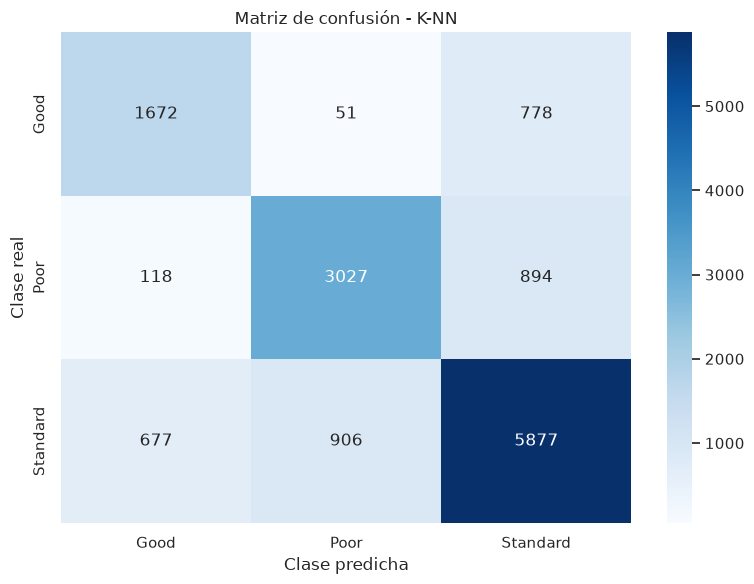

In [10]:
# La diagonal principal representa los aciertos.
# Los valores fuera de la diagonal representan errores.
classes = sorted(y.unique())

cm = confusion_matrix(
    y_valid,
    y_valid_pred,
    labels=classes
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.title("Matriz de confusión - K-NN")
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.tight_layout()
plt.show()

## 10. Comparación de clases reales y predichas

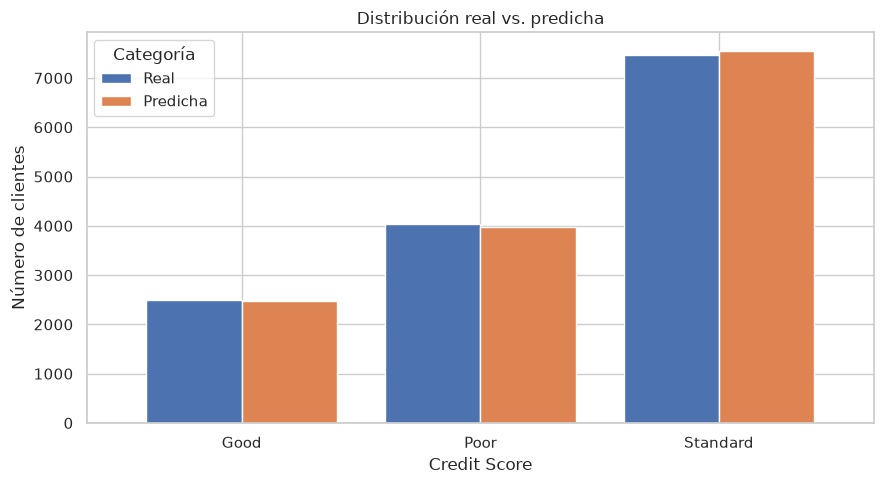

In [11]:
# Comparar cuántos ejemplos de cada clase existen realmente
# y cuántos fueron asignados a esa clase por el modelo.
comparison = pd.DataFrame({
    "Real": y_valid.to_numpy(),
    "Predicha": y_valid_pred
})

comparison_counts = pd.concat(
    [
        comparison["Real"].value_counts().rename("Real"),
        comparison["Predicha"].value_counts().rename("Predicha")
    ],
    axis=1
).fillna(0)

comparison_counts = comparison_counts.reindex(
    classes,
    fill_value=0
)

comparison_counts.plot(
    kind="bar",
    figsize=(9, 5),
    width=0.8
)

plt.title("Distribución real vs. predicha")
plt.xlabel("Credit Score")
plt.ylabel("Número de clientes")
plt.xticks(rotation=0)
plt.legend(title="Categoría")
plt.tight_layout()
plt.show()

## 11. Porcentaje de errores por clase


Errores por clase:
            Aciertos  Total  Errores  Error (%)
Clase real                                     
Good            1672   2501      829      33.15
Poor            3027   4039     1012      25.06
Standard        5877   7460     1583      21.22


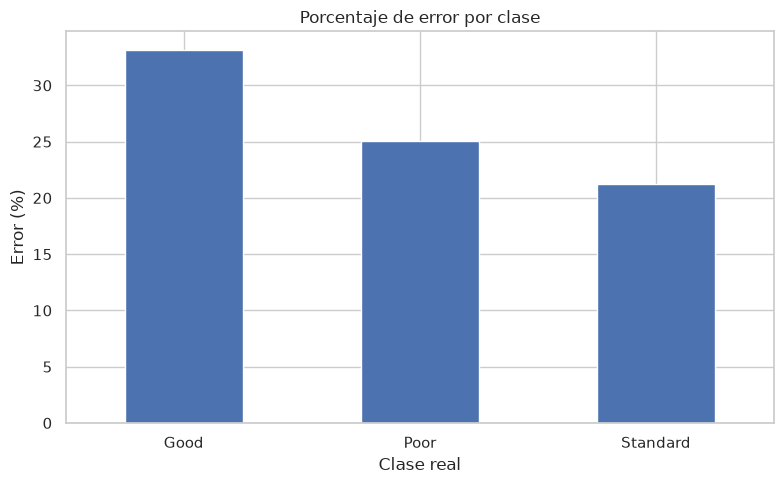

In [12]:
# Comprobar en qué clases reales se equivoca más el modelo.
results = pd.DataFrame({
    "Clase real": y_valid.to_numpy(),
    "Clase predicha": y_valid_pred
})

results["Correcto"] = (
    results["Clase real"] == results["Clase predicha"]
)

# Calcular aciertos y total de casos por clase real.
errors_by_class = results.groupby("Clase real")["Correcto"].agg(
    Aciertos="sum",
    Total="count"
)

errors_by_class["Errores"] = (
    errors_by_class["Total"] - errors_by_class["Aciertos"]
)

errors_by_class["Error (%)"] = (
    errors_by_class["Errores"]
    / errors_by_class["Total"]
    * 100
)

print("\nErrores por clase:")
print(errors_by_class.round(2))

errors_by_class["Error (%)"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Porcentaje de error por clase")
plt.xlabel("Clase real")
plt.ylabel("Error (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 12. Visualización PCA en dos dimensiones

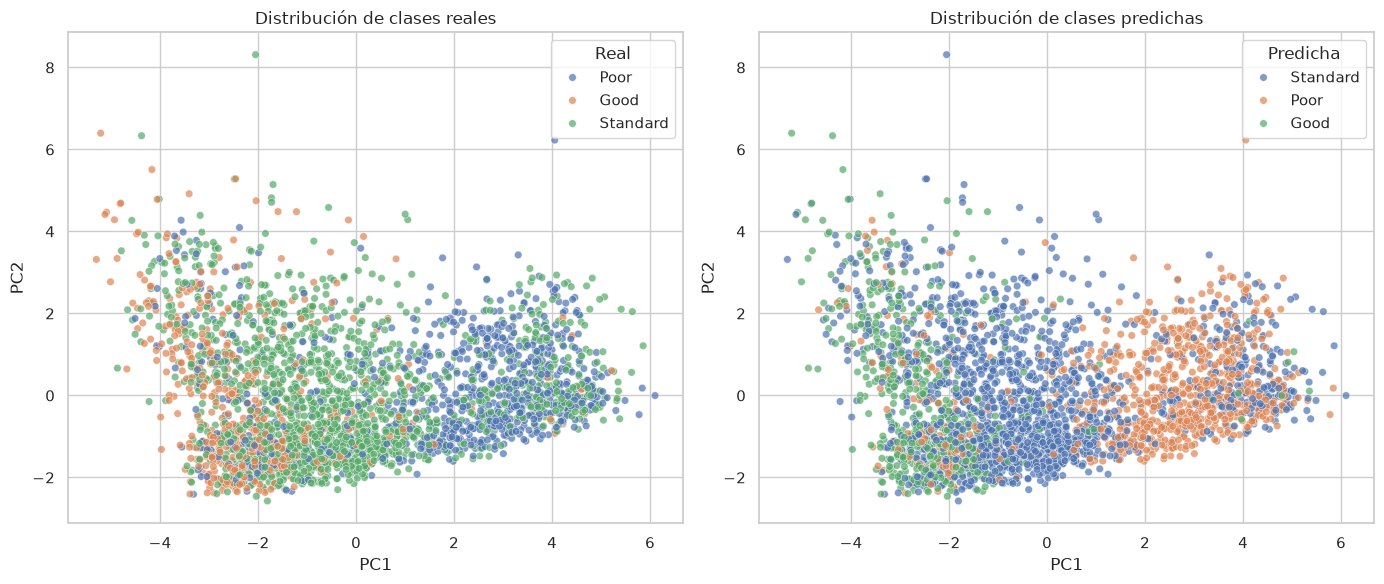

Varianza explicada por los dos componentes: 40.97%


In [13]:
# PCA permite observar una proyección bidimensional de los datos.
# Esta proyección es aproximada y no muestra todas las dimensiones.
# Limitamos la cantidad de filas para reducir el consumo de memoria.

MAX_PCA_ROWS = 3000

# Aplicar el preprocesamiento ya ajustado durante el entrenamiento.
X_valid_transformed = knn_pipeline.named_steps[
    "preprocessor"
].transform(X_valid)

# Seleccionar una muestra reproducible si hay demasiadas filas.
if X_valid_transformed.shape[0] > MAX_PCA_ROWS:
    rng = np.random.default_rng(RANDOM_STATE)

    sample_idx = np.sort(
        rng.choice(
            X_valid_transformed.shape[0],
            size=MAX_PCA_ROWS,
            replace=False
        )
    )
else:
    sample_idx = np.arange(X_valid_transformed.shape[0])

X_pca_input = X_valid_transformed[sample_idx]

# Convertir a formato denso solo después de reducir la muestra.
if sparse.issparse(X_pca_input):
    X_pca_input = X_pca_input.toarray()

# Reducir las variables a dos componentes principales.
pca = PCA(
    n_components=2,
    random_state=RANDOM_STATE
)

X_valid_pca = pca.fit_transform(X_pca_input)

# Preparar las clases reales y predichas para el gráfico.
pca_df = pd.DataFrame({
    "PC1": X_valid_pca[:, 0],
    "PC2": X_valid_pca[:, 1],
    "Real": y_valid.iloc[sample_idx].to_numpy(),
    "Predicha": y_valid_pred[sample_idx]
})

# Mostrar dos gráficos para comparar la distribución de las clases.
fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 6)
)

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Real",
    alpha=0.7,
    s=30,
    ax=axes[0]
)

axes[0].set_title("Distribución de clases reales")

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Predicha",
    alpha=0.7,
    s=30,
    ax=axes[1]
)

axes[1].set_title("Distribución de clases predichas")

plt.tight_layout()
plt.show()

# Indicar qué porcentaje de la variación retienen los dos componentes.
explained_variance = pca.explained_variance_ratio_.sum() * 100

print(
    "Varianza explicada por los dos componentes: "
    f"{explained_variance:.2f}%"
)

## 13. Entrenamiento final y generación de submission

In [14]:
# Después de evaluar el modelo, entrenarlo con todos los datos etiquetados.
print("\nEntrenando modelo final con todos los datos...")
knn_pipeline.fit(X, y)

# Predecir las clases de los datos de prueba.
test_preds = knn_pipeline.predict(X_submission)

# Comprobar que exista una predicción por cada fila de prueba.
if len(sample_sub) != len(test_preds):
    raise ValueError(
        "El número de filas de sample_submission no coincide "
        "con el número de predicciones."
    )

# Conservar la estructura y los identificadores del archivo de ejemplo.
submission = sample_sub.copy()

# Identificar la columna que contiene las predicciones.
candidate_cols = [
    col for col in submission.columns
    if col.lower() in {
        "class",
        "credit_score",
        "creditscore",
        "target"
    }
]

if len(candidate_cols) == 1:
    target_col = candidate_cols[0]

elif len(submission.columns) == 2:
    # Si hay dos columnas, se asume que la última es la variable objetivo.
    target_col = submission.columns[-1]

else:
    raise ValueError(
        "No se pudo identificar la columna objetivo. "
        "Revisa las columnas de sample_submission: "
        f"{submission.columns.tolist()}"
    )

# Guardar las predicciones en un CSV.
submission[target_col] = test_preds

submission.to_csv(
    "submission.csv",
    index=False
)

print("\n" + "=" * 60)
print("PROCESO COMPLETADO")
print("=" * 60)
print("Archivo generado: submission.csv")
print("Dimensiones:", submission.shape)
print("\nPrimeras predicciones:")
print(submission.head())


Entrenando modelo final con todos los datos...

PROCESO COMPLETADO
Archivo generado: submission.csv
Dimensiones: (30000, 2)

Primeras predicciones:
   id class
0   1  Good
1   2  Poor
2   3  Good
3   4  Poor
4   5  Good
